In [803]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,        # vocabulary size
    "context_length": 1024,     # context length
    "emb_dim": 768,             # embedding dimension
    "n_heads": 12,              # number of attention heads
    "n_layers": 12,             # number of layers i.e number of transformer blocks
    "drop_rate": 0.1,           # dropout rate
    "qkv_bias": False           # Query-Key-Value bias
}

In [804]:
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_emb = nn.Embedding(config["vocab_size"], config["emb_dim"])
        self.pos_emb = nn.Embedding(config["context_length"], config["emb_dim"])
        self.drop_emb = nn.Dropout(config["drop_rate"])

        # Use a placeholder for Transformer Block
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(config) for _ in range(config["n_layers"])]
        )

        # Use a placeholder for Layer Norm
        self.final_norm = DummyLayerNorm(config["emb_dim"])
        self.out_head = nn.Linear(config["emb_dim"], config["vocab_size"], bias = False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embds = self.token_emb(in_idx)
        pos_embds = self.pos_emb(torch.arange(seq_len, device = in_idx.device))
        x = tok_embds + pos_embds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)

        return logits


class DummyTransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()

        # A simple placeholder

    def forward(self, x):

        # This block does nothing just return its inputs

        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps = 1e-5):
        super().__init__()

        # The parmeters here just to mimic the layer norm interface

    def forward(self, x):

        # This layer does nothing and just return its inputs

        return x

In [805]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))

batch = torch.stack(batch, dim = 0)

print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [806]:
batch.shape

torch.Size([2, 4])

In [807]:
torch.manual_seed(123)

model = DummyGPTModel(config = GPT_CONFIG_124M)

logits = model(batch)
print("Output shape: ", logits.shape)
print(logits)

Output shape:  torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6754, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


### Normalizing activations with layer normalization

In [808]:
torch.manual_seed(123)

batch_example = torch.randn(2,5)

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)

print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [809]:
mean = out.mean(dim = -1, keepdim = True)
var = out.var(dim = -1, keepdim = True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [810]:
out_norm = (out - mean) / torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

mean = out_norm.mean(dim = -1, keepdim = True)
var = out_norm.var(dim = -1, keepdim = True)

print("Mean:\n", mean)
print("Variance: \n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance: 
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [811]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [812]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim = -1, keepdim = True)
        var = x.var(dim = -1, keepdim = True)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)

        return self.scale * norm_x + self.shift

 - Scale and shift

    - Note that in addition to performing the normalization by subtracting the mean and dividing by the variance, we added two trainable parameters, a scale and a shift parameter
  
    - The initial scale (multiplying by 1) and shift (adding 0) values don't have any effect; however, scale and shift are trainable parameters that the LLM automatically adjusts during training if it is determined that doing so would improve the model's performance on its training task

    - This allows the model to learn appropriate scaling and shifting that best suit the data it is processing

    - Note that we also add a smaller value (eps) before computing the square root of the variance; this is to avoid division-by-zero errors if the variance is 0
  

- Biased variance

    - In the variance calculation above, setting unbiased=False means using the formula to compute the variance where n is the sample size (here, the number of features or columns); this formula does not include Bessel's correction (which uses n-1 in the denominator), thus providing a biased estimate of the variance

    - For LLMs, where the embedding dimension n is very large, the difference between using n and n-1 is negligible

    - However, GPT-2 was trained with a biased variance in the normalization layers, which is why we also adopted this setting for compatibility reasons with the pretrained weights that we will load in later chapters

In [813]:
ln = LayerNorm(emb_dim=6)
out_ln = ln(out)

In [814]:
mean = out_ln.mean(dim = -1, keepdim = True)
var = out_ln.var(dim = -1, unbiased = True, keepdim = True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9996],
        [0.9997]], grad_fn=<VarBackward0>)


### Implementing a feed forward network with GELU activations

In [815]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))

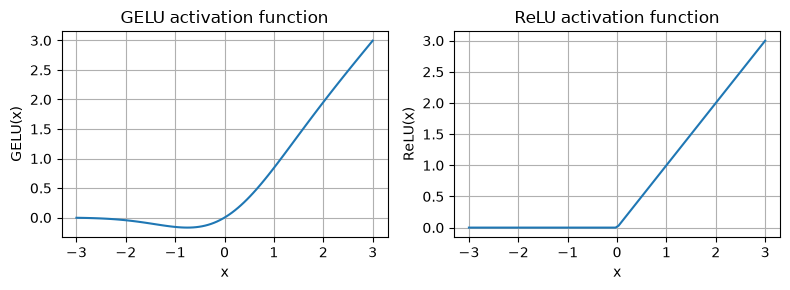

In [816]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [817]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(config["emb_dim"], 4 * config["emb_dim"]),
            GELU(),
            nn.Linear(4 * config["emb_dim"], config["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)

In [818]:
ffn = FeedForward(GPT_CONFIG_124M)

In [819]:
x = torch.rand(2, 3, 768)

ffn(x).shape

torch.Size([2, 3, 768])

In [820]:
ffn.layers

Sequential(
  (0): Linear(in_features=768, out_features=3072, bias=True)
  (1): GELU()
  (2): Linear(in_features=3072, out_features=768, bias=True)
)

In [821]:
ffn.layers[0]

Linear(in_features=768, out_features=3072, bias=True)

In [822]:
ffn.layers[0].weight

Parameter containing:
tensor([[-0.0223,  0.0308,  0.0022,  ..., -0.0174, -0.0227, -0.0178],
        [-0.0027, -0.0043, -0.0274,  ...,  0.0079,  0.0112,  0.0010],
        [-0.0029,  0.0175,  0.0244,  ..., -0.0164, -0.0300,  0.0045],
        ...,
        [ 0.0255,  0.0023,  0.0277,  ..., -0.0037, -0.0134, -0.0284],
        [ 0.0266,  0.0236, -0.0193,  ...,  0.0120,  0.0061, -0.0261],
        [ 0.0222,  0.0106, -0.0190,  ..., -0.0253,  0.0320, -0.0109]],
       requires_grad=True)

### Adding Shortcut connections

In [823]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x

In [824]:
def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)
    
    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [825]:
layer_sizes = [3, 3, 3, 3, 3, 1]

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)

model_without_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut = False)

print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


In [826]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


### Connecting Attention and linear layers in a transformer block

In [827]:
from multiheadattention import MultiHeadAttention

class TransformerBlock(nn.Module):

    def __init__(self, config):

        super().__init__()

        self.attention = MultiHeadAttention(input_dimension = config["emb_dim"], output_dimension = config["emb_dim"], context_length = config["context_length"], num_heads = config["n_heads"], dropout = config["drop_rate"], qkv_bias = config["qkv_bias"])

        self.feed_forward = FeedForward(config)

        self.norm1 = LayerNorm(config["emb_dim"])
        
        self.norm2 = LayerNorm(config["emb_dim"])

        self.drop_shortcut = nn.Dropout(config["drop_rate"])


    def forward(self, x):

        # Shortcut connection for attention block
        shortcut = x

        x = self.norm1(x)

        x = self.attention(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        # Shortcut connection for feed forward block
        shortcut = x

        x = self.norm2(x)

        x = self.feed_forward(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        return x

In [828]:
torch.manual_seed(123)

x = torch.rand(2, 4, 768)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape: ", x.shape)
print("Output shape: ", output.shape)

Input shape:  torch.Size([2, 4, 768])
Output shape:  torch.Size([2, 4, 768])


### Coding the GPT Model

In [829]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))

batch = torch.stack(batch, dim = 0)

print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [830]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))

In [831]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(config["emb_dim"], 4 * config["emb_dim"]),
            GELU(),
            nn.Linear(4 * config["emb_dim"], config["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)

In [832]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim = -1, keepdim = True)
        var = x.var(dim = -1, keepdim = True)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)

        return self.scale * norm_x + self.shift

In [833]:
from multiheadattention import MultiHeadAttention

class TransformerBlock(nn.Module):

    def __init__(self, config):

        super().__init__()

        self.attention = MultiHeadAttention(input_dimension = config["emb_dim"], output_dimension = config["emb_dim"], context_length = config["context_length"], num_heads = config["n_heads"], dropout = config["drop_rate"], qkv_bias = config["qkv_bias"])

        self.feed_forward = FeedForward(config)

        self.norm1 = LayerNorm(config["emb_dim"])
        
        self.norm2 = LayerNorm(config["emb_dim"])

        self.drop_shortcut = nn.Dropout(config["drop_rate"])


    def forward(self, x):

        # Shortcut connection for attention block
        shortcut = x

        x = self.norm1(x)

        x = self.attention(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        # Shortcut connection for feed forward block
        shortcut = x

        x = self.norm2(x)

        x = self.feed_forward(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        return x

In [834]:
import torch
import torch.nn as nn

class GPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_emb = nn.Embedding(config["vocab_size"], config["emb_dim"])
        self.pos_emb = nn.Embedding(config["context_length"], config["emb_dim"])
        self.drop_emb = nn.Dropout(config["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(config) for _ in range(config["n_layers"])]
        )
        
        self.final_norm = LayerNorm(config["emb_dim"])
        self.out_head = nn.Linear(config["emb_dim"], config["vocab_size"], bias = False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embds = self.token_emb(in_idx)
        pos_embds = self.pos_emb(torch.arange(seq_len, device = in_idx.device))
        x = tok_embds + pos_embds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)

        return logits

In [835]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)

out = model(batch)

In [836]:
batch.shape

torch.Size([2, 4])

In [837]:
batch.numel()

8

In [838]:
out.shape

torch.Size([2, 4, 50257])

In [839]:
total_params = sum(p.numel() for p in model.parameters())

total_params

163009536

In [840]:
print(total_params - model.out_head.weight.numel())

124412160


- GPT2-small (the 124M configuration we already implemented):

    - "emb_dim" = 768
    - "n_layers" = 12
    - "n_heads" = 12

- GPT2-medium:

    - "emb_dim" = 1024
    - "n_layers" = 24
    - "n_heads" = 16

- GPT2-large:
    - "emb_dim" = 1280
    - "n_layers" = 36
    - "n_heads" = 20

- GPT2-XL:
    - "emb_dim" = 1600
    - "n_layers" = 48
    - "n_heads" = 25

### Generate Text

In [841]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):
        
        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]
        
        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)
        
        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]  

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

In [842]:
start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [ ]:
model.eval() # disable dropout

out = generate_text_simple(model = model, idx = encoded_tensor, max_new_tokens = 6, context_size = GPT_CONFIG_124M["context_length"])

print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


In [844]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue
